# 4. Transformer Decoder

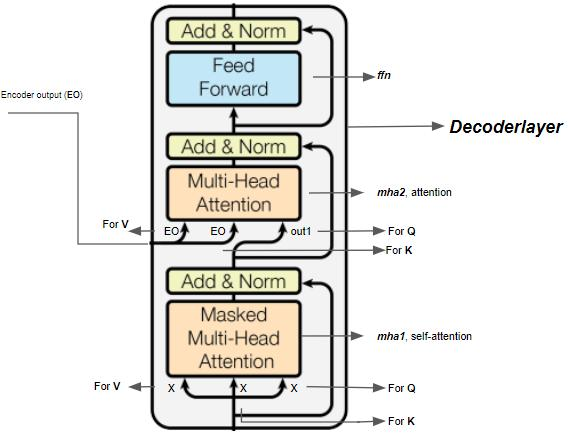
The **Transformer decoder** generates the target sequence using:

1. **Masked Multi-Head Self-Attention**
2. **Cross-Attention**
3. **Feed-Forward Network**
4. **Residual Connections**
5. **Layer Normalization**

The decoder is different from the encoder because it must generate the target **autoregressively** and therefore must not look at future target tokens.



---

## 4.1 High-Level Decoder Architecture

```text
Target Tokens
      ↓
Masked Multi-Head Self-Attention
      ↓
Add & LayerNorm
      ↓
Cross-Attention
      ↓
Add & LayerNorm
      ↓
Feed-Forward Network
      ↓
Add & LayerNorm
      ↓
Decoder Output
```

The complete decoder layer can be visualized as:

```text
                         Encoder Output
                              │
                              │ K, V
                              ▼
Target ──► Masked Self-Attention ──► Cross-Attention
              │                         │
              ▼                         ▼
          Add & Norm                Add & Norm
                                         │
                                         ▼
                                      FFN
                                         │
                                         ▼
                                    Add & Norm
                                         │
                                         ▼
                                      Output
```

---

# 4.2 Masked Self-Attention

The first sublayer of the decoder is **masked self-attention**.

The decoder needs to look at previously generated tokens, but it must **not look at future tokens**.

For example, when predicting:

```text
"I love machine ___"
```

the decoder can use:

```text
"I"
"I love"
"I love machine"
```

but it cannot use the correct future word:

```text
"I love machine learning"
                  ↑
             future token
```

### Why?

If the decoder could see the future target tokens during training, it could simply copy the answer instead of learning to predict it.

---

## 4.3 Causal Mask

A causal mask prevents each position from attending to future positions.

For a sequence of 4 tokens:

```text
t₁  t₂  t₃  t₄
```

the attention pattern is conceptually:

```text
        Keys
        t₁  t₂  t₃  t₄
      ┌───────────────
t₁    │ ✓   ✗   ✗   ✗
t₂    │ ✓   ✓   ✗   ✗
t₃    │ ✓   ✓   ✓   ✗
t₄    │ ✓   ✓   ✓   ✓
```

So:

- \(t_1\) can attend only to \(t_1\)
- \(t_2\) can attend to \(t_1,t_2\)
- \(t_3\) can attend to \(t_1,t_2,t_3\)
- \(t_4\) can attend to \(t_1,t_2,t_3,t_4\)

This is called **causal** or **autoregressive masking**.

---

## 4.4 Masking in the Attention Equation

Recall:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

Before applying softmax, the model masks future positions.

Conceptually:

$$
S = \frac{QK^T}{\sqrt{d_k}}
$$

Then:

$$
S_{ij} = -\infty
\quad \text{for } j>i
$$

After softmax:

$$
\operatorname{softmax}(-\infty) \approx 0
$$

Therefore, future tokens receive effectively zero attention probability.

---

# 4.5 Residual Connection + LayerNorm

After masked self-attention:

```text
Target Input
     │
     ├──────────────────┐
     ↓                  │
Masked Self-Attention   │
     │                  │
     └──────► Add ◄─────┘
                ↓
            LayerNorm
```

Conceptually:

$$
Y =
\operatorname{LayerNorm}
\left(
X+\operatorname{MaskedMHA}(X)
\right)
$$

The residual connection provides a direct path for the original representation.

---

# 4.6 Cross-Attention

The second attention mechanism in the decoder is **cross-attention**.

This connects the decoder to the encoder.

```text
                  Encoder
                     │
                     │ K, V
                     ▼
              ┌─────────────┐
Decoder Q ──► │Cross-Attention│
              └─────────────┘
                     │
                     ▼
              Decoder Output
```

The key relationship is:

$$
Q = \text{Decoder representation}
$$

$$
K,V = \text{Encoder representations}
$$

Therefore:

$$
\operatorname{CrossAttention}
=
\operatorname{Attention}
(Q_{\text{decoder}},
K_{\text{encoder}},
V_{\text{encoder}})
$$

---

## 4.7 Why Cross-Attention?

Consider machine translation:

```text
Source:
"The cat is sleeping"

Target:
"Le chat dort"
```

While generating `"chat"`, the decoder can use cross-attention to identify relevant information in the encoded source.

Conceptually:

```text
Decoder token
     │
     │ Query
     ▼
Cross-Attention
     ▲
     │
Encoder representations
"The" "cat" "is" "sleeping"
```

The decoder can therefore selectively retrieve information from the source sequence.

---

# 4.8 Cross-Attention Residual + LayerNorm

After cross-attention:

```text
Previous Decoder Representation
              │
              ├──────────────────┐
              ↓                  │
       Cross-Attention           │
              │                  │
              └──────► Add ◄─────┘
                         ↓
                     LayerNorm
```

Conceptually:

$$
Z =
\operatorname{LayerNorm}
\left(
Y+\operatorname{CrossAttention}
(Y,H,H)
\right)
$$

where:

- \(Y\) = decoder representation
- \(H\) = encoder output

---

# 4.9 Feed-Forward Network

After cross-attention, the decoder applies a position-wise Feed-Forward Network.

```text
Input
  ↓
Linear
  ↓
Activation
  ↓
Linear
  ↓
Output
```

A general formulation is:

$$
\operatorname{FFN}(x)
=
W_2\sigma(W_1x+b_1)+b_2
$$

In the original Transformer:

$$
\operatorname{FFN}(x)
=
\operatorname{ReLU}(xW_1+b_1)W_2+b_2
$$

The FFN operates independently on each position.

---

# 4.10 Final Residual Connection + LayerNorm

After the FFN:

```text
Cross-Attention Output
        │
        ├──────────────────┐
        ↓                  │
       FFN                 │
        │                  │
        └──────► Add ◄─────┘
                   ↓
               LayerNorm
                   ↓
                 Output
```

Conceptually:

$$
O =
\operatorname{LayerNorm}
\left(
Z+\operatorname{FFN}(Z)
\right)
$$

---

# 4.11 Complete Decoder Layer

Putting everything together:

```text
                         Encoder Output
                              │
                              │ K, V
                              ▼
Target Input ──► Masked Self-Attention
                       │
                       ▼
                  Add & Norm
                       │
                       ▼
                 Cross-Attention ◄── Encoder Output
                       │
                       ▼
                  Add & Norm
                       │
                       ▼
               Feed-Forward Network
                       │
                       ▼
                  Add & Norm
                       │
                       ▼
                     Output
```

The mathematical flow can be summarized as:

$$
Y =
\operatorname{LayerNorm}
\left(
X+\operatorname{MaskedMHA}(X)
\right)
$$

$$
Z =
\operatorname{LayerNorm}
\left(
Y+\operatorname{CrossAttention}(Y,H,H)
\right)
$$

$$
O =
\operatorname{LayerNorm}
\left(
Z+\operatorname{FFN}(Z)
\right)
$$

where \(H\) represents the encoder output.

---

# 4.12 Encoder vs Decoder

| Feature | Encoder | Decoder |
|---|---|---|
| Self-attention | Yes | Yes |
| Self-attention type | Unmasked | **Masked/Causal** |
| Cross-attention | No | **Yes** |
| FFN | Yes | Yes |
| Residual connections | Yes | Yes |
| LayerNorm | Yes | Yes |
| Main role | Understand source | Generate target |

The most important difference is:

```text
Encoder:
Self-Attention

Decoder:
Masked Self-Attention
        +
Cross-Attention
```

---

# 4.13 Why Does the Decoder Need Two Attention Mechanisms?

This is a very important conceptual question.

### Masked self-attention

Answers:

> **"What have I generated so far?"**

```text
Previous target tokens
          ↓
Masked Self-Attention
```

### Cross-attention

Answers:

> **"What information from the source is relevant right now?"**

```text
Encoder output
      ↓
Cross-Attention
      ↑
Decoder representation
```

Together:

```text
             Decoder
                │
       ┌────────┴────────┐
       ↓                 ↓
Masked Self-Attn    Cross-Attention
       │                 │
"What have I       "What does the
generated?"         source tell me?"
       │                 │
       └────────┬────────┘
                ↓
              FFN
                ↓
         Next-token prediction
```

---

# 4.14 Decoder During Training vs Inference

### Training

During training, the target sequence is available.

For:

```text
"I love NLP"
```

the model can train using shifted inputs:

```text
Input:  <START> I love
Target: I       love NLP
```

The causal mask prevents each position from seeing future target tokens.

### Inference

The model generates tokens one at a time:

```text
<START>
   ↓
I
   ↓
I love
   ↓
I love NLP
   ↓
<END>
```

Therefore, autoregressive generation remains sequential.

---

# Interview Points 🎯

### What is the purpose of masked self-attention?

> It prevents the decoder from attending to future target tokens, ensuring autoregressive generation.

### Why does the decoder need cross-attention?

> Cross-attention allows the decoder to retrieve relevant information from the encoder's representations.

### Where do \(Q,K,V\) come from in decoder cross-attention?

$$
Q \leftarrow \text{Decoder}
$$

$$
K,V \leftarrow \text{Encoder}
$$

### Why does the decoder have two attention mechanisms?

> Masked self-attention models relationships among previously generated target tokens, while cross-attention connects the target generation process to the source sequence.

---

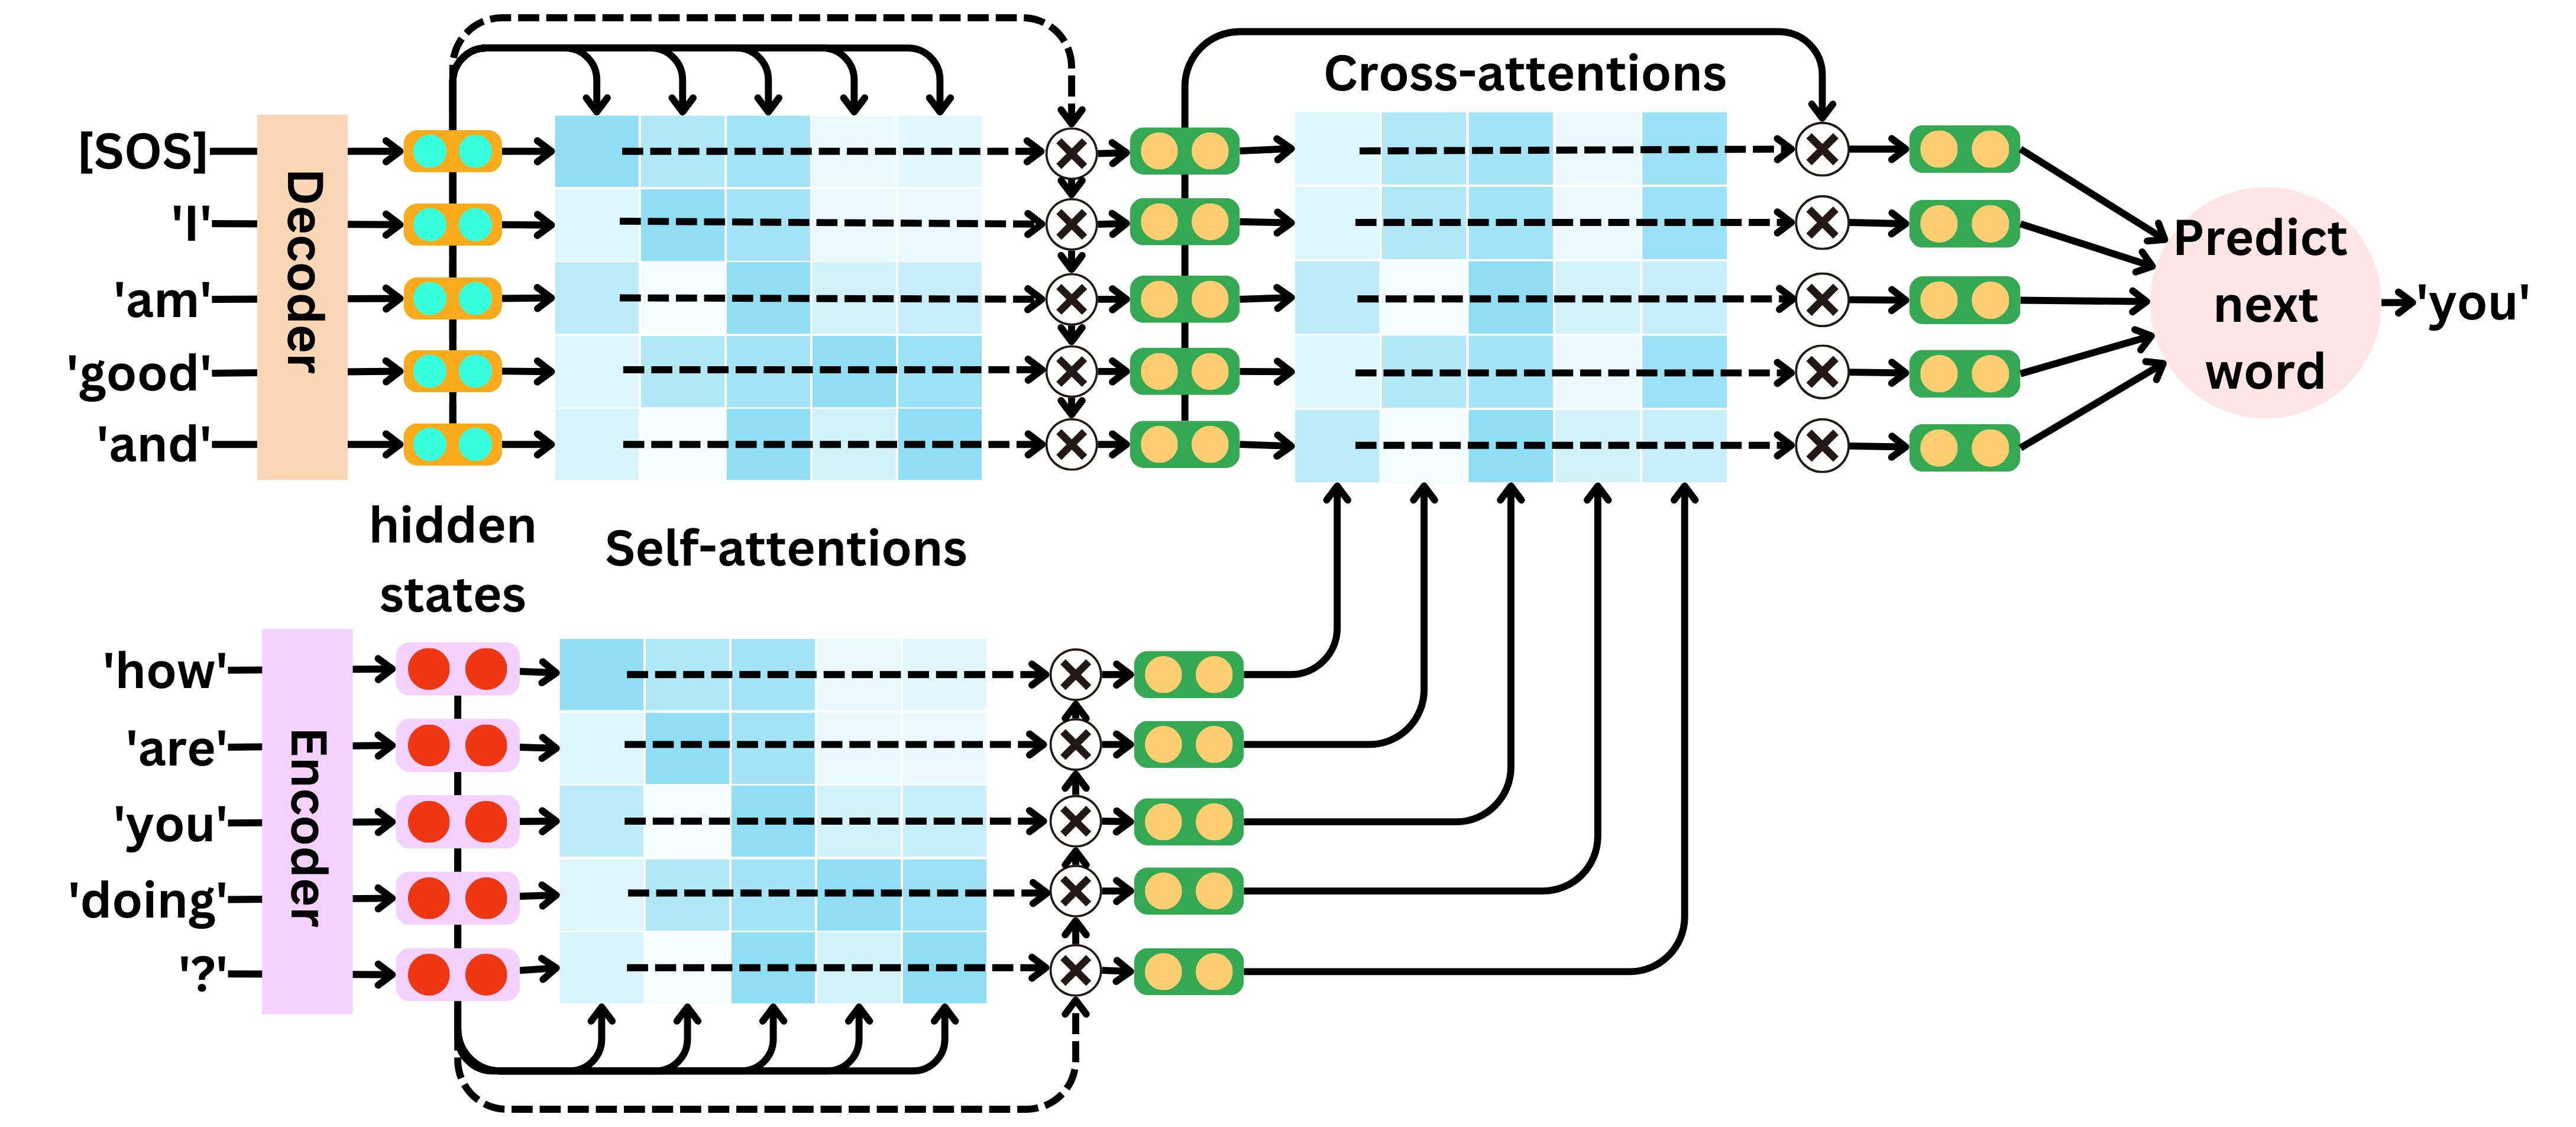

# What You Should Remember

1. The Transformer decoder has **three main sublayers**:
   - Masked self-attention
   - Cross-attention
   - Feed-forward network

2. **Masked self-attention** prevents access to future target tokens.

3. **Cross-attention** connects the decoder to the encoder.

4. In cross-attention:

$$
Q=\text{Decoder}
$$

$$
K,V=\text{Encoder}
$$

5. Each decoder sublayer uses **residual connections and LayerNorm**.

6. The decoder generates the target sequence **autoregressively**.

7. The key difference from the encoder is:

```text
Encoder
→ Self-Attention

Decoder
→ Masked Self-Attention
→ Cross-Attention
```

8. The complete decoder flow is:

```text
Target
  ↓
Masked Self-Attention
  ↓
Add & Norm
  ↓
Cross-Attention
  ↓
Add & Norm
  ↓
FFN
  ↓
Add & Norm
  ↓
Output
```

---